# Imports and Setup

In [1]:
%load_ext autoreload

import logging
logging.basicConfig(level=logging.INFO, format='%(asctime)s - %(levelname)s - %(message)s') # NOTSET, DEBUG, INFO, WARN, ERROR, CRITICAL

import os
import numpy as np

os.environ["JAX_PLATFORM_NAME"] = "cpu"  # must be set before importing jax

import jax
import jax.numpy as jnp
from jax import vmap, jit, grad, jacfwd

# Optional: higher numeric accuracy (do this before heavy JAX use)
# try:
#     from jax import config as jax_config
#     jax_config.update("jax_enable_x64", True)
# except Exception:
#     pass

import skewerjax as sjx

import matplotlib as mpl
from matplotlib.collections import LineCollection
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
plt.style.use('tableau-colorblind10')
font, rcnew = sjx.config.setup_matplotlib.matplotlib_default_config()
plt.rc('font', **font)
plt.rcParams.update(rcnew)
%matplotlib widget

INFO:2026-03-06 10:22:39,154:jax._src.xla_bridge:752: Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: libtpu.so: cannot open shared object file: No such file or directory
2026-03-06 10:22:39,154 - INFO - Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: libtpu.so: cannot open shared object file: No such file or directory
2026-03-06 10:22:39,337 - INFO - SkewerBundle class definition complete


In [2]:
from skewerjax.skewers.skewers import SkewerBundle
from skewerjax.cosmology.cosmology import Cosmology

from skewerjax.fields.fields import ScalarField, VectorField, Fields
import skewerjax.fields.toy_model_samplers as toy_samplers
import skewerjax.utils.aux as aux
import skewerjax.utils.plotting_tools as pt

import skewerjax.optical_depth.optical_depth as od

from skewerjax.constants.physical_constants import phys

# Auxiliary objects that would be employed throughout the notebook

In [3]:
x_axis_key = "log_lambda"
assert x_axis_key in ("wavelengths", "velocities", "log_lambda"), "x_axis_key should be either 'wavelengths', 'velocities' or 'log_lambda'"

### Define radiation domination cosmology to employ in the different examples that require it

In [4]:
# Create cosmology object
cosmology = Cosmology(H0=phys.H0, Omega_r_0=9.1436e-5, Omega_m_0=0.3089, Omega_k_0=0.0, Omega_lambda_0=0.6911)
# Define which cosmology to use, this is set as default to 0 since skewer and cosmology objects can deal with multiple cosmologies at once, 
# but other classes such as fields and optical depth are currently only set up for a single cosmology at a time
ii_cosmology = 0

### Define wavelength range and lines to study

In [5]:
line_bundle = sjx.constants.lines.LineBundle(["HI-LyA", "SiIII-1206", "SiII-1190", "SiII-1193"])

### Auxiliary variables

In [6]:
L_box = 51.7  # Mpc

In [7]:
T0_HI = 1e5
T0_Si = 2e6

n0_min = 1e-16
n0_max = 1e-10

def pk_template(k: jnp.ndarray, A, n, k0, k_cut):
    # P(k) = A (k/k0)^n exp[-(k/k_cut)^2]
    kk = jnp.maximum(k, 1e-12)
    return A * (kk / k0) ** n * jnp.exp(-(kk / k_cut) ** 2)

number_density_sampler = toy_samplers.number_density_sampler_gaussian_3d(
    key=jax.random.PRNGKey(0),
    pk_of_k=lambda k: pk_template(k, A=5.0, n=-2.5, k0=2.0, k_cut=50.0),
    n0_min=n0_min, n0_max=n0_max, L_box=L_box,
    grid_shape=(256, 256, 256), contrast=1.2,
)

In [8]:
fields = Fields({
    "HI": {
        "temperature": ScalarField(toy_samplers.temperature_sampler(T0_HI, T0_HI, L_box)),    # UNITS: [K]
        "velocity": VectorField(toy_samplers.velocity_sampler(0.0, 0.0, L_box)),        # UNITS: [km/s]
        "number_density": ScalarField(number_density_sampler),                          # [cm^-3]
        "turbulence": ScalarField(toy_samplers.turbulence_sampler(b_turb=0.0)),         # UNITS: [km/s]
        "collisional": ScalarField(toy_samplers.collisional_sampler(A_coll=0.0))        # UNITS: [GHz]
    },
    "SiIII": {
        "temperature": ScalarField(toy_samplers.temperature_sampler(T0_Si, T0_Si, L_box)),    # UNITS: [K]
        "velocity": VectorField(toy_samplers.velocity_sampler(0.0, 0.0, L_box)),        # UNITS: [km/s]
        "number_density": ScalarField(number_density_sampler),                          # [cm^-3]
        "turbulence": ScalarField(toy_samplers.turbulence_sampler(b_turb=0.0)),         # UNITS: [km/s]
        "collisional": ScalarField(toy_samplers.collisional_sampler(A_coll=0.0))        # UNITS: [GHz]
    },
    "SiII": {
        "temperature": ScalarField(toy_samplers.temperature_sampler(T0_Si, T0_Si, L_box)),    # UNITS: [K]
        "velocity": VectorField(toy_samplers.velocity_sampler(0.0, 0.0, L_box)),        # UNITS: [km/s]
        "number_density": ScalarField(number_density_sampler),                          # [cm^-3]
        "turbulence": ScalarField(toy_samplers.turbulence_sampler(b_turb=0.0)),         # UNITS: [km/s]
        "collisional": ScalarField(toy_samplers.collisional_sampler(A_coll=0.0))        # UNITS: [GHz]
    },
})

In [9]:
ICs = jnp.ones(cosmology.N_cosmologies)
scale_factor_start = float(cosmology.solve_a_of_x(ICs, jnp.linspace(start=0.0, stop=-L_box, num=2))[0, -1])

In [10]:
lambda0_anchor_key = None
if lambda0_anchor_key == "Ly-\alpha":
    lambda0_anchor = line_bundle.lines_for_species('HI')[0].lambda0_A
elif lambda0_anchor_key == None:
    lambda0_anchor = 1

In [11]:
delta_lambda_limits = 1.0
min_lambda = jnp.min(line_bundle.lambda0_A) - delta_lambda_limits
max_lambda = jnp.max(line_bundle.lambda0_A)/scale_factor_start + delta_lambda_limits

resolution_lambda_A = 0.02 # in Angstroms
N_lambda = int((max_lambda - min_lambda) / resolution_lambda_A)

if x_axis_key == "log_lambda":
    wavelengths = jnp.geomspace(min_lambda, max_lambda, N_lambda)  # in Angstroms
else:
    wavelengths = jnp.linspace(min_lambda, max_lambda, N_lambda)  # in Angstroms

In [12]:
if x_axis_key == "wavelengths":
    x_label = r"$\lambda\ [\mathrm{\AA}]$"
    min_plot = min_lambda
    max_plot = max_lambda
elif x_axis_key == "velocities":
    x_label = r"Velocity space [$\mathrm{km\,/\,s}$]"
    min_plot = (min_lambda - line_bundle.lambda0_A[0]) / (line_bundle.lambda0_A[0]) * phys.c_km_s
    max_plot = (max_lambda*scale_factor_start - line_bundle.lambda0_A[0]) / (line_bundle.lambda0_A[0]*scale_factor_start) * phys.c_km_s
elif x_axis_key == "log_lambda":
    if lambda0_anchor_key == "Ly-\alpha":
        x_label = r"$\log_{10}( \frac{\lambda a_\mathrm{QSO}}{\lambda_\dagger a_0})$"
        min_plot = jnp.log10(min_lambda*scale_factor_start)
        max_plot = jnp.log10(max_lambda*scale_factor_start/lambda0_anchor)
    elif lambda0_anchor_key == None:
        x_label = r"$\log_{10}(\lambda \frac{a_\mathrm{QSO}}{a_0} \left[\mathrm{\AA}\right])$"
        min_plot = jnp.log10(min_lambda)
        max_plot = jnp.log10(max_lambda/scale_factor_start)

In [13]:
save_path_global = "/home/STORAGE/SKEWERS/PLOTS/toy_metals/"
os.makedirs(save_path_global, exist_ok=True)

# Generate figures for gif

In [ ]:
N_imshow = 1024
points_grid_imshow = aux.make_plane_points(L_box, 'x', L_box/2, N_imshow, N_imshow)
log10_number_density_imshow = np.log10(fields.number_density(jnp.concatenate([jnp.ones((N_imshow, N_imshow, 1)), points_grid_imshow], axis=-1)))

N_grid_skewers = 3
N_ppsk = N_imshow
points_grid_skewers = aux.make_skewer_grid_points(L_box, N_grid_skewers, N_ppsk, direction="y")
a0_per_skewer = 1.0 # scale factor at which ICs are defined, same for all skewers
x0_per_skewer = 0.0 # comoving distance at which ICs are defined, same for all skewers

ic = N_grid_skewers//2
jc = N_grid_skewers//2

density_norm = mpl.colors.Normalize(
    vmin=float(np.min(log10_number_density_imshow)),
    vmax=float(np.max(log10_number_density_imshow)),
)

skewer_cmap = mpl.cm.get_cmap("gist_rainbow")
skewer_norm = mpl.colors.Normalize(vmin=0.0, vmax=float(N_ppsk - 1))

L_box = float(points_grid_imshow[..., 1].max() - points_grid_imshow[..., 1].min())

list_plot = range(1, N_ppsk, 8) # plot one each 2 N_ppsk
list_plot = [(N_ppsk-1)//2, N_ppsk-1]

if len(list_plot) < 5:
    show_plots = True
else:
    show_plots = False

for ii in list_plot:

    _N_ppsk = ii + 1
    _points_grid_skewers = points_grid_skewers[:, :, 0:_N_ppsk, :]

    _points = jnp.reshape(_points_grid_skewers, (N_grid_skewers*N_grid_skewers, _N_ppsk, 3))
    
    skewer_bundle = SkewerBundle(spatial_points=_points, cosmologies=cosmology, a0=a0_per_skewer, x0=x0_per_skewer)
    optical_depth = od.compute_optical_depth(skewer_bundle, wavelengths, line_bundle, fields) # Compute optical depth
    F_over_F0 = jnp.reshape(jnp.exp(-optical_depth), (line_bundle.n_lines, N_grid_skewers, N_grid_skewers, len(wavelengths)))

    points_central = skewer_bundle.spatial_points[ic * N_grid_skewers + jc]
    log10_number_density_central = np.log10(fields.number_density(jnp.concatenate([jnp.ones(points_central.shape[0:1])[..., None], points_central], axis=-1)))
    F_over_F0_central = F_over_F0[..., ic * N_grid_skewers + jc]

    fig1, axes1 = pt.plot_density_imshow_and_central_profile(
        points_central=np.asarray(points_central),
        points_grid_imshow=np.asarray(points_grid_imshow),
        log10_number_density_imshow=np.asarray(log10_number_density_imshow),
        log10_number_density_central=np.asarray(log10_number_density_central),
        line_bundle=line_bundle,
        savepath_png=os.path.join(save_path_global, f"density_{ii}.png"),
        density_norm=density_norm,
        box_limits_yz=((0.0, L_box), (0.0, L_box)),
        box_limits_los=(0.0, L_box),
        skewer_cmap=skewer_cmap, skewer_norm=skewer_norm, show=show_plots,
    )

    _scale_factors = np.asarray(skewer_bundle.scale_factors[0, ic * N_grid_skewers + jc], dtype=float)
    scale_factor_ratio = float(_scale_factors[-1] / _scale_factors[0])

    fig2, axes2 = pt.plot_flux_panels(
        wavelengths=wavelengths, F_over_F0=np.asarray(F_over_F0),
        ic=ic, jc=jc, line_bundle=line_bundle,
        scale_factor_ratio=scale_factor_ratio,
        x_axis_key=x_axis_key, min_x=min_plot, max_x=max_plot, lambda0_anchor=lambda0_anchor,
        savepath_png=os.path.join(save_path_global, f"flux_split_{ii}.png"),
        skewer_cmap=skewer_cmap, skewer_norm=skewer_norm,
        skewer_last_index=ii,  # "last" point shown in this iteration
        show=show_plots,
    )

    fig, ax = pt.plot_flux_panels_colored_by_los(
        wavelengths=wavelengths, F_over_F0=np.asarray(F_over_F0),
        ic=ic, jc=jc, line_bundle=line_bundle,
        x_axis_key=x_axis_key, skewer_bundle=skewer_bundle, min_x=min_plot, max_x=max_plot,
        skewer_last_index=ii,
        N_grid_skewers=N_grid_skewers, lambda0_anchor=lambda0_anchor,
        skewer_cmap=skewer_cmap, skewer_norm=skewer_norm,
        savepath_png=os.path.join(save_path_global, f"flux_combined_{ii}.png"),
        show=show_plots,
    )

In [ ]:
if x_axis_key == "wavelengths":
    x_axis_array = np.asarray(wavelengths, dtype=float)
elif x_axis_key == "velocities":
    x_axis_array = phys.c*1e-3 * (wavelengths*scale_factor_ratio - lambda0_anchor) / (lambda0_anchor*scale_factor_ratio) # km/s
elif x_axis_key == "log_lambda":
    x_axis_array = np.log10(wavelengths*scale_factor_ratio / lambda0_anchor)

In [ ]:
linestyles = ["-", "--", "-.", ":", (0, (3, 1, 1, 1)), (0, (5, 1))]

fig, ax = plt.subplots(figsize=(10, 4.5))
legend_handles, legend_labels = [], []
for i_line, line in enumerate(line_bundle.lines):
    ls = linestyles[i_line % len(linestyles)]

    lam0_rest = float(line.lambda0_A)
    lamf_rest = lam0_rest * scale_factor_ratio
    if x_axis_key == "wavelengths":
        x0 = lam0_rest
        xf = lamf_rest
    elif x_axis_key == "velocities":
        x0 = phys.c*1e-3 * (lam0_rest * scale_factor_ratio - lambda0_anchor) / (lambda0_anchor * scale_factor_ratio)
        xf = phys.c*1e-3 * (lamf_rest * scale_factor_ratio - lambda0_anchor) / (lambda0_anchor * scale_factor_ratio)
    elif x_axis_key == "log_lambda":
        x0 = np.log10(lam0_rest*scale_factor_ratio / lambda0_anchor)
        xf = np.log10(lamf_rest*scale_factor_ratio / lambda0_anchor)
    ax.axvline(x0, color="grey", linestyle=linestyles[i_line], lw=1.5, alpha=1.0)
    ax.axvline(xf, color="grey", linestyle=linestyles[i_line], lw=1.5, alpha=1.0)

    ax.plot(x_axis_array, F_over_F0[i_line, ic, jc, :], color="royalblue", lw=1.5, linestyle=ls, zorder=2)

    name = getattr(line, "name", None) or getattr(line, "label", None) or f"Line {i_line}"
    legend_handles.append(Line2D([0], [0], color="royalblue", lw=2.2, linestyle=ls))
    legend_labels.append(name)

ax.set_xlim(float(np.min(x_axis_array)), float(np.max(x_axis_array)))
ax.set_ylim([-0.05, 1.05])

ax.set_xlabel(x_label, fontsize=20)
ax.set_ylabel(r"$e^{-\tau}$", fontsize=20)

ax.tick_params(which="both", direction="in", top=True, right=True, length=7, width=1.6, labelsize=18)
ax.tick_params(which="minor", length=4)
for spine in ax.spines.values():
    spine.set_linewidth(1.8)

ax.legend(
    legend_handles, legend_labels, loc="lower right", fontsize=16, handlelength=2.6, handletextpad=0.6, borderaxespad=0.6, ncols=1
)

fig.tight_layout()

savepath_png = os.path.join(save_path_global, "flux_separate_taus.png")
d = os.path.dirname(savepath_png)
if d:
    os.makedirs(d, exist_ok=True)
fig.savefig(savepath_png, dpi=200, bbox_inches="tight")

plt.show()

In [ ]:
optical_depth_total = jnp.sum(optical_depth, axis=0)

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4.5))
for i_line, line in enumerate(line_bundle.lines):
    ls = linestyles[i_line % len(linestyles)]

    lam0_rest = float(line.lambda0_A)
    lamf_rest = lam0_rest * scale_factor_ratio
    if x_axis_key == "wavelengths":
        x0 = lam0_rest
        xf = lamf_rest
    elif x_axis_key == "velocities":
        x0 = phys.c*1e-3 * (lam0_rest * scale_factor_ratio - lambda0_anchor) / (lambda0_anchor * scale_factor_ratio)
        xf = phys.c*1e-3 * (lamf_rest * scale_factor_ratio - lambda0_anchor) / (lambda0_anchor * scale_factor_ratio)
    elif x_axis_key == "log_lambda":
        x0 = np.log10(lam0_rest*scale_factor_ratio / lambda0_anchor)
        xf = np.log10(lamf_rest*scale_factor_ratio / lambda0_anchor)
    ax.axvline(x0, color="grey", linestyle=linestyles[i_line], lw=1.5, alpha=1.0)
    ax.axvline(xf, color="grey", linestyle=linestyles[i_line], lw=1.5, alpha=1.0)

ax.plot(x_axis_array, jnp.exp(-optical_depth_total[ic * N_grid_skewers + jc, :]), color="royalblue", lw=1.5, linestyle='-', zorder=2)

ax.set_xlim(float(np.min(x_axis_array)), float(np.max(x_axis_array)))
ax.set_ylim([-0.05, 1.05])

ax.set_xlabel(x_label, fontsize=20)
ax.set_ylabel(r"$e^{-\tau}$", fontsize=20)

ax.tick_params(which="both", direction="in", top=True, right=True, length=7, width=1.6, labelsize=18)
ax.tick_params(which="minor", length=4)
for spine in ax.spines.values():
    spine.set_linewidth(1.8)

fig.tight_layout()

savepath_png = os.path.join(save_path_global, "flux_total.png")
d = os.path.dirname(savepath_png)
if d:
    os.makedirs(d, exist_ok=True)
fig.savefig(savepath_png, dpi=200, bbox_inches="tight")

plt.show()

# Compute $\xi$

In [14]:
N_grid_skewers = 32
N_ppsk = 1024
points_grid_skewers = aux.make_skewer_grid_points(L_box, N_grid_skewers, N_ppsk, direction="y")
points = jnp.reshape(points_grid_skewers, (N_grid_skewers*N_grid_skewers, N_ppsk, 3))
skewer_bundle = SkewerBundle(spatial_points=points, cosmologies=cosmology)

2026-03-06 10:22:50,507 - INFO - Initializing SkewerBundle with 1024 skewers, 1024 points per skewer
2026-03-06 10:22:50,532 - INFO - Broadcasting scalar ICs_defined_at_index=-1 to all 1024 skewers
2026-03-06 10:22:50,545 - INFO - All skewers set to absorption mode
2026-03-06 10:22:50,579 - INFO - Computing los_directions automatically from spatial coordinate differences
2026-03-06 10:22:50,736 - INFO - Computing comoving distances along skewer direction
2026-03-06 10:22:50,868 - INFO - Computing scale factors from cosmology
2026-03-06 10:22:51,984 - INFO - Storing quadri-vectors
2026-03-06 10:22:52,029 - INFO - SkewerBundle initialization complete


In [15]:
ICs = jnp.ones(cosmology.N_cosmologies)
scale_factor_start = float(cosmology.solve_a_of_x(ICs, jnp.linspace(start=0.0, stop=-L_box, num=2))[0, -1])

In [16]:
delta_lambda_limits = 1.0
min_lambda = jnp.min(line_bundle.lambda0_A) - delta_lambda_limits
max_lambda = jnp.max(line_bundle.lambda0_A)/scale_factor_start + delta_lambda_limits

resolution_lambda_A = 0.05 # in Angstroms
N_lambda = int((max_lambda - min_lambda) / resolution_lambda_A)

if x_axis_key == "log_lambda":
    wavelengths = jnp.geomspace(min_lambda, max_lambda, N_lambda)  # in Angstroms
else:
    wavelengths = jnp.linspace(min_lambda, max_lambda, N_lambda)  # in Angstroms

In [17]:
_scale_factors = np.asarray(skewer_bundle.scale_factors[0, 0], dtype=float)
scale_factor_ratio = float(_scale_factors[-1] / _scale_factors[0])

In [18]:
if x_axis_key == "wavelengths":
    x_label = r"$\lambda\ [\mathrm{\AA}]$"
    x_axis_array = np.asarray(wavelengths, dtype=float)
elif x_axis_key == "velocities":
    x_label = r"Velocity space [$\mathrm{km\,/\,s}$]"
    x_axis_array = phys.c*1e-3 * (wavelengths*scale_factor_ratio - lambda0_anchor) / (lambda0_anchor*scale_factor_ratio) # km/s
elif x_axis_key == "log_lambda":
    if lambda0_anchor_key == "Ly-\alpha":
        x_label = r"$\log_{10}( \frac{\lambda a_\mathrm{QSO}}{\lambda_\mathrm{Ly-\alpha}}/ )$"
    elif lambda0_anchor_key == None:
        x_label = r"$\log_{10}(\lambda \frac{a_\mathrm{QSO}}{a_0}  \left[\mathrm{\AA}\right])$"
    x_axis_array = np.log10(wavelengths*scale_factor_ratio / lambda0_anchor)

In [19]:
array_size_bytes = N_lambda * skewer_bundle.N_sk * skewer_bundle.N_ppsk * line_bundle.n_lines * jnp.dtype(jnp.float64).itemsize
array_size_GB = array_size_bytes / 1e9
print(array_size_GB)

import psutil
memory_size = psutil.virtual_memory().total
memory_size_GB = memory_size / 1e9
print(memory_size_GB)

28.152168448
134.869372928


In [20]:
optical_depth = od.compute_optical_depth(skewer_bundle, wavelengths, line_bundle, fields) # Compute optical depth
F_over_F0 = jnp.exp(-optical_depth)

2026-03-06 10:22:54,751 - INFO - [OPTICAL_DEPTH] Starting computation for cosmology index 0, Voigt impl=ExoJAX
2026-03-06 10:22:54,752 - INFO - [OPTICAL_DEPTH] Extracting 1024 skewers with 1024 points each
2026-03-06 10:22:54,789 - INFO - [OPTICAL_DEPTH] Computing line profiles for 4 lines across 3 species
2026-03-06 10:22:56,539 - INFO - [OPTICAL_DEPTH] Line profiles computed with shape (4, 1024, 1024, 839)
2026-03-06 10:22:56,540 - INFO - [OPTICAL_DEPTH] Tiling fields for 3 species to line-level
2026-03-06 10:23:22,941 - INFO - [OPTICAL_DEPTH] Tiled number_density with shape (4, 1024, 1024)
2026-03-06 10:23:22,942 - INFO - [OPTICAL_DEPTH] Computing dtau_dx with constant 2.654009e-03 nm²/ns
2026-03-06 10:23:23,213 - INFO - [OPTICAL_DEPTH] dtau_dx computed with shape (4, 1024, 1024, 839)
2026-03-06 10:23:23,215 - INFO - [OPTICAL_DEPTH] Reorienting 1024 skewers based on photon path direction mask
2026-03-06 10:23:23,483 - INFO - [OPTICAL_DEPTH] Arrays reoriented: quadri_vectors (1024, 1

In [21]:
# -----------------------
# Pick a subset of N skewers
# -----------------------
N_plot_sample = 4
seed = 0
rng = np.random.default_rng(seed)

N_lines, N_skewers, N_lambda = optical_depth.shape
idx = np.arange(N_skewers) if N_plot_sample >= N_skewers else rng.choice(N_skewers, size=N_plot_sample, replace=False)
idx = np.array(idx, dtype=int)
print("Selected skewer indices:", idx)

# colors: one color per selected skewer
cmap = plt.get_cmap("tab10")
colors = {ii: cmap(j % cmap.N) for j, ii in enumerate(idx)}

Selected skewer indices: [276 522 868 650]


In [22]:
linestyles = ["--", ":", "-.", (0, (3, 1, 1, 1)), (0, (5, 1))]

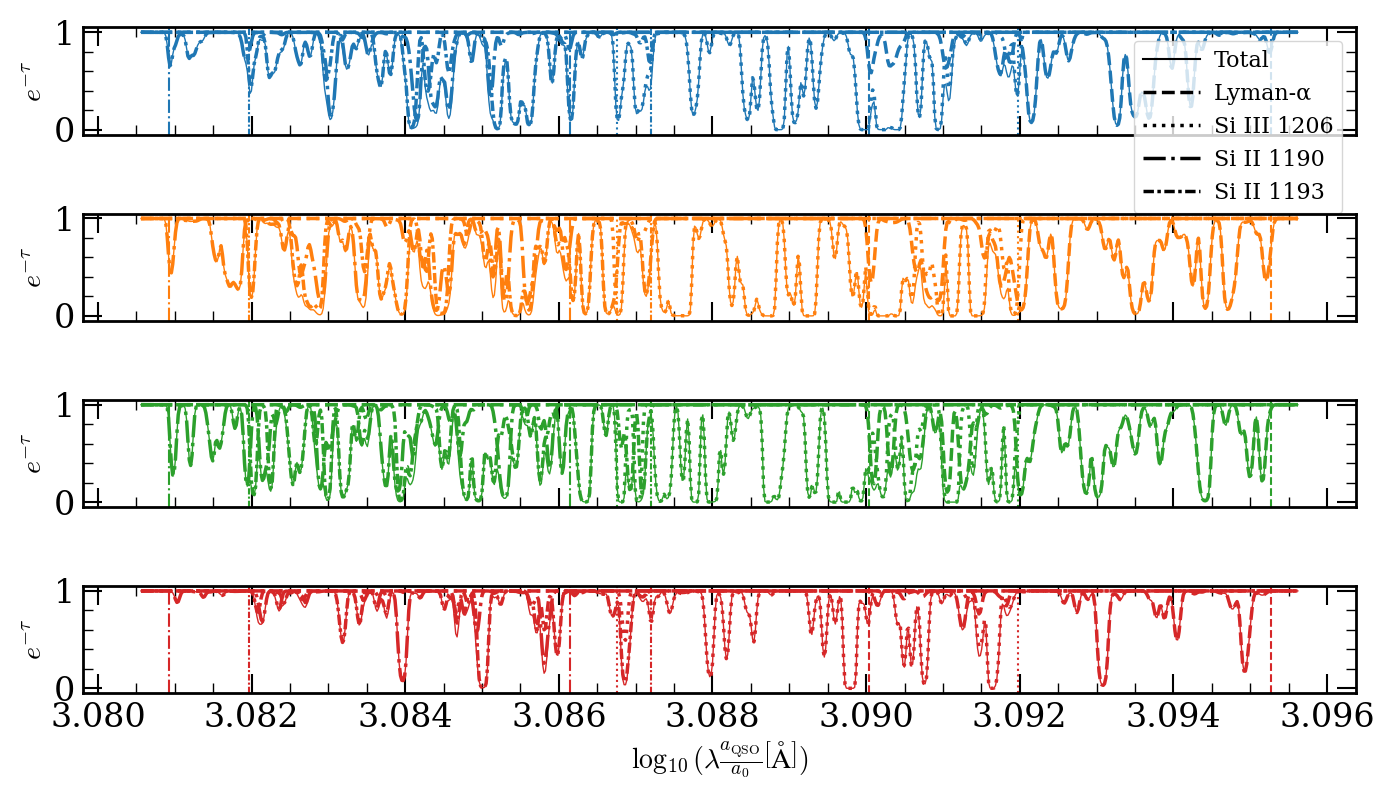

In [23]:
list_handles = [Line2D([0], [0], color='k', lw=1.5, linestyle='-', label='Total')]
fig, axes = plt.subplots(N_plot_sample, 1, figsize=(14, 2*N_plot_sample), sharex=True, sharey=True)
for ii, _idx in enumerate(idx):
    ax = axes[ii]

    _F = np.prod(F_over_F0[:, _idx, :], axis=0)
    ax.plot(x_axis_array, _F, color=colors[_idx], lw=1.0, linestyle='-', alpha=1.0)
    
    for i_line, line in enumerate(line_bundle.lines):

        ax.plot(x_axis_array, F_over_F0[i_line, _idx, :], color=colors[_idx], lw=2.5, linestyle=linestyles[i_line])

        ls = linestyles[i_line % len(linestyles)]
        
        lam0 = float(line.lambda0_A)
        lamf = lam0 * scale_factor_ratio
        if x_axis_key == "wavelengths":
            lam0 = lam0
            lamf = lamf
        if x_axis_key == "velocities":
            lam0 = phys.c*1e-3 * (lam0*scale_factor_ratio - lambda0_anchor) / (lambda0_anchor*scale_factor_ratio) # km/s
            lamf = phys.c*1e-3 * (lamf*scale_factor_ratio - lambda0_anchor) / (lambda0_anchor*scale_factor_ratio) # km/s
        elif x_axis_key == "log_lambda":
            lam0 = np.log10(lam0*scale_factor_ratio / lambda0_anchor)
            lamf = np.log10(lamf*scale_factor_ratio / lambda0_anchor)
        ax.axvline(lam0, color=colors[_idx], linestyle=linestyles[i_line], lw=1.5, alpha=1.0)
        ax.axvline(lamf, color=colors[_idx], linestyle=linestyles[i_line], lw=1.5, alpha=1.0)

        if ii == 0:
            name = getattr(line, "name", None) or getattr(line, "label", None) or f"Line {i_line}"
            list_handles.append(Line2D([0], [0], color='k', lw=2.5, linestyle=ls, label=name))

    ax.set_ylim([-0.05, 1.05])
    ax.set_ylabel(r"$e^{-\tau}$", fontsize=20)
ax.set_xlabel(x_label, fontsize=20)

# custom legend
axes[0].legend(handles=list_handles, loc='upper right', fontsize=16, handlelength=2.6, handletextpad=0.6, borderaxespad=0.6, ncols=1)

savepath_png = os.path.join(save_path_global, "skewer_exsamples.png")
d = os.path.dirname(savepath_png)
if d:
    os.makedirs(d, exist_ok=True)
fig.savefig(savepath_png, dpi=200, bbox_inches="tight")

plt.tight_layout()
plt.show()

In [24]:
import skewerjax.summary_stats.xi1D as xi1D

In [25]:
# 2PCF settings
n_bins = 256
r_min = 0.0
r_max = float(x_axis_array.max() - x_axis_array.min())*0.8
include_self = False
center = True
standardize = False
chunk_size = 1 << 15

In [26]:
# 1) Precompute geometry ONCE
pb = xi1D.precompute_pair_binning_1d(
    x_axis_array, n_bins=n_bins, r_min=r_min, r_max=r_max, include_self=include_self, chunk_size=chunk_size,
)
r_centers = pb.r_centers

xi_auto = {}
xi_cross = {}          # only i<j stored here
xi_cross_diag = {}     # i==i stored here for validation

# 2) Auto for "total"
xi_auto["total"] = xi1D.two_point_corr_1d_from_precomp(
    pb, jnp.prod(F_over_F0, axis=0), center=center, standardize=standardize,
)

# 3) Auto for each line
for i, line in enumerate(line_bundle.lines):
    name = line.name
    xi_auto[name] = xi1D.two_point_corr_1d_from_precomp(
        pb, F_over_F0[i], center=center, standardize=standardize,
    )

# 4) Cross only for unique pairs (i<j), no repetition. Store as xi_cross[name_i][name_j] with i<j.
for i, line_i in enumerate(line_bundle.lines):
    name_i = line_i.name
    xi_cross[name_i] = {}
    
    for j in range(i + 1, len(line_bundle.lines)):
        name_j = line_bundle.lines[j].name
        xi_cross[name_i][name_j] = xi1D.two_point_corr_1d_cross_from_precomp(
            pb, F_over_F0[i], F_over_F0[j], center=center, standardize=standardize,
            symmetrize=True,  # this is ξ_{αX} symmetric definition
        )

2026-03-06 10:23:37,592 - INFO - precompute_pair_binning_1d: N=839, n_bins=256, include_self=False, periodic_L=None, chunk_size=32768
2026-03-06 10:23:37,971 - INFO - Pairs: n_pairs=351541, n_chunks=11, n_pad=360448 (pad_len=8907)
2026-03-06 10:23:38,153 - INFO - two_point_corr_1d_from_precomp: N_samples=1024, N_x=839, n_bins=256, n_chunks=11, acc_dtype=float32
2026-03-06 10:23:38,332 - INFO - two_point_corr_1d_from_precomp: N_samples=1024, N_x=839, n_bins=256, n_chunks=11, acc_dtype=float32
2026-03-06 10:23:38,382 - INFO - two_point_corr_1d_from_precomp: N_samples=1024, N_x=839, n_bins=256, n_chunks=11, acc_dtype=float32
2026-03-06 10:23:38,441 - INFO - two_point_corr_1d_from_precomp: N_samples=1024, N_x=839, n_bins=256, n_chunks=11, acc_dtype=float32
2026-03-06 10:23:38,494 - INFO - two_point_corr_1d_from_precomp: N_samples=1024, N_x=839, n_bins=256, n_chunks=11, acc_dtype=float32


/home/dlopez/tmp/pip-tmp/ipykernel_358508/130138293.py:62: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


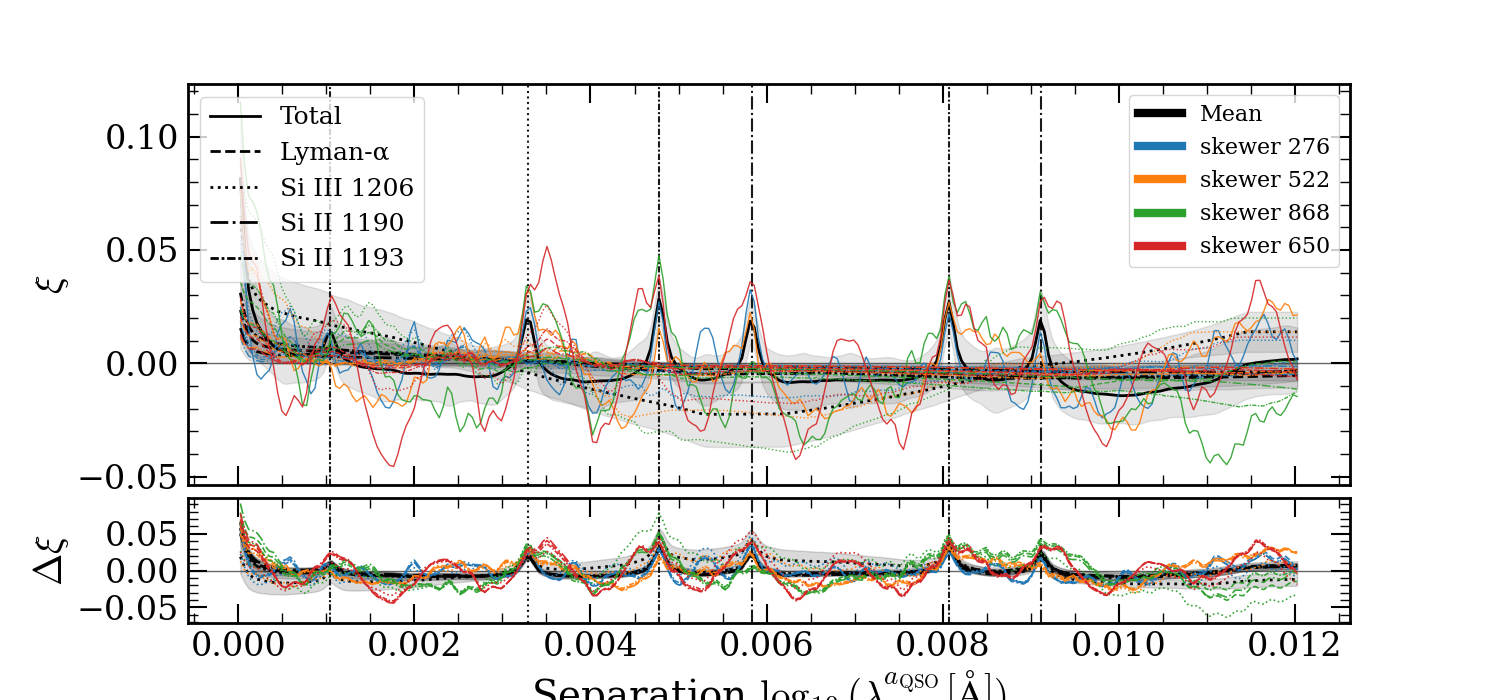

In [27]:
fig, (ax, axr) = plt.subplots(
    2, 1, figsize=(15, 7.0), sharex=True, gridspec_kw={"height_ratios": [3.2, 1.0], "hspace": 0.05}
)

mean_all, std_all = np.nanmean(xi_auto['total'], axis=0), np.nanstd(xi_auto['total'], axis=0)
ax.plot(r_centers, mean_all, lw=2.0, c="k", ls='-')
ax.fill_between(r_centers, (mean_all - std_all), (mean_all + std_all), alpha=0.10, color="k")

style_handles = [Line2D([0], [0], color="k", lw=2.0, ls='-', label="Total")]
for i_line, line in enumerate(line_bundle.lines):
    mean_line, std_line = np.nanmean(xi_auto[line.name], axis=0), np.nanstd(xi_auto[line.name], axis=0)
    ax.plot(r_centers, mean_line, lw=2.0, c="k", ls=linestyles[i_line])
    ax.fill_between(r_centers, (mean_line - std_line), (mean_line + std_line), alpha=0.10, color="k")
    axr.plot(r_centers, (mean_all - mean_line), color="k", lw=2.0, alpha=0.95, ls=linestyles[i_line])
    axr.fill_between(r_centers, (mean_all - mean_line) - std_line, (mean_all - mean_line) + std_line, color="k", alpha=0.15)

    style_handles.append(Line2D([0], [0], color="k", lw=2.0, ls=linestyles[i_line], label=line.name))

    lambda0_A_i = float(line.lambda0_A)
    for j_line, line_j in enumerate(line_bundle.lines):
        if j_line <= i_line:
            continue
        
        lambda0_A_j = float(line_j.lambda0_A)

        if x_axis_key == "wavelengths":
            expected_cross_peak = abs(lambda0_A_i - lambda0_A_j)
        elif x_axis_key == "velocities":
            expected_cross_peak = phys.c*1e-3 * abs(lambda0_A_i - lambda0_A_j) / (lambda0_anchor) # km/s
        elif x_axis_key == "log_lambda":
            expected_cross_peak = np.log10(lambda0_A_i / lambda0_A_j)

        ax.axvline(np.abs(expected_cross_peak), color="k", linestyle=linestyles[j_line], lw=1.5, alpha=0.9)
        axr.axvline(np.abs(expected_cross_peak), color="k", linestyle=linestyles[j_line], lw=1.5, alpha=0.9)

leg1 = ax.legend(handles=style_handles, loc="upper left", frameon=True, fontsize=18)
ax.add_artist(leg1)

ax.axhline(0.0, color="k", lw=1.0, alpha=0.6)
axr.axhline(0.0, color="k", lw=1.0, alpha=0.6)
ax.set_ylabel(r"$\xi$")
axr.set_xlabel(r"Separation " + x_label)
axr.set_ylabel(r"$\Delta\xi$")

for ii, _idx in enumerate(idx):
    ax.plot(r_centers, xi_auto['total'][ii], color=colors[_idx], lw=1.0, alpha=0.9, ls='-')
    for i_line, line in enumerate(line_bundle.lines):
        ax.plot(r_centers, xi_auto[line.name][ii], color=colors[_idx], lw=1.0, alpha=0.9, ls=linestyles[i_line])
        axr.plot(r_centers, (xi_auto['total'][ii] - xi_auto[line.name][ii]), color=colors[_idx], lw=1.2, alpha=0.95, ls=linestyles[i_line])
  
color_handles = [Line2D([0],[0], color="k", lw=6.0, ls='-',  label="Mean")]
for ii in idx:
    color_handles.append(Line2D([0],[0], color=colors[ii], lw=6.0, label=f"skewer {ii}"))
ax.legend(handles=color_handles, loc="upper right", frameon=True, fontsize=16)

savepath_png = os.path.join(save_path_global, "xi1D.png")
d = os.path.dirname(savepath_png)
if d:
    os.makedirs(d, exist_ok=True)
fig.savefig(savepath_png, dpi=200, bbox_inches="tight")

plt.tight_layout()
plt.show()

/home/dlopez/tmp/pip-tmp/ipykernel_358508/3842243531.py:82: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


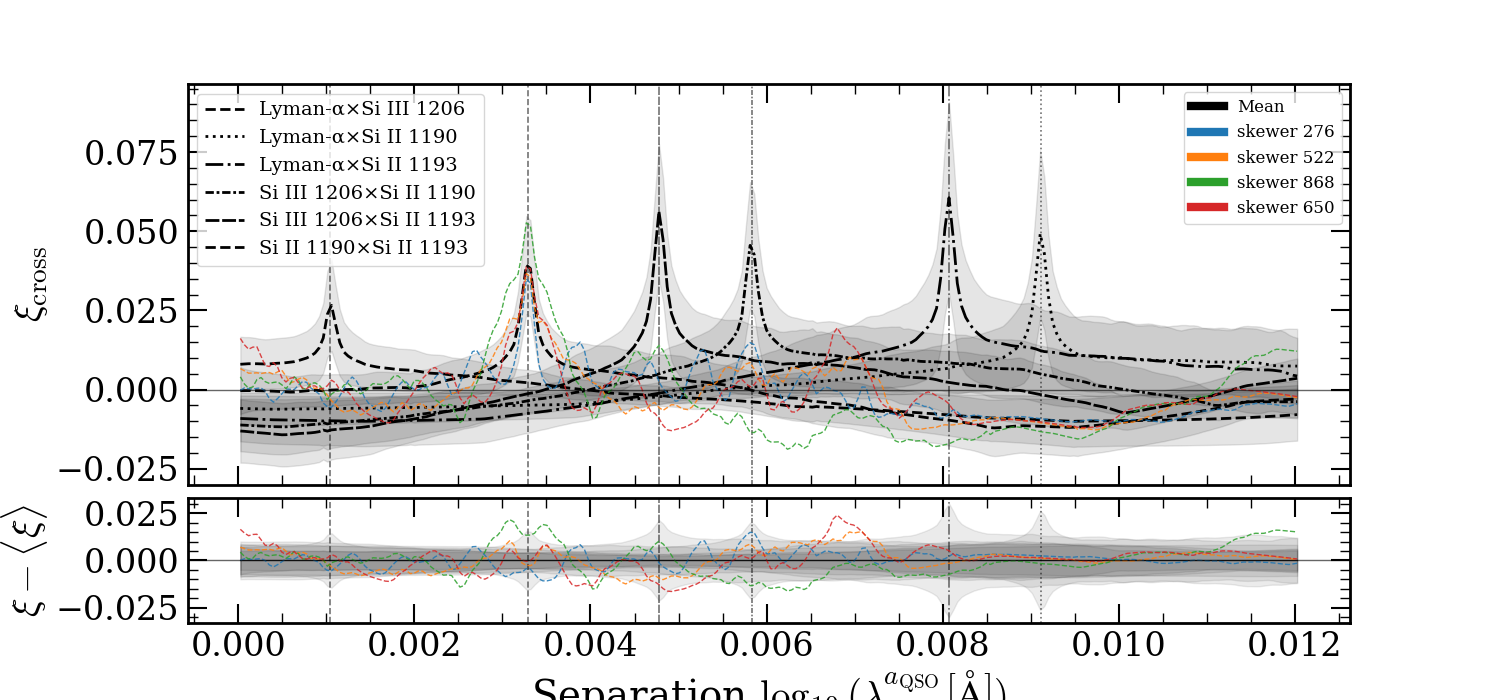

In [28]:
# quick lookup for rest wavelengths
line_by_name = {ln.name: ln for ln in line_bundle.lines}

pairs = []
for name_i in xi_cross:
    for name_j in xi_cross[name_i]:
        pairs.append((name_i, name_j))   # only unique i<j if you built it that way

fig, (ax, axr) = plt.subplots(
    2, 1, figsize=(15, 7.0),
    sharex=True,
    gridspec_kw={"height_ratios": [3.2, 1.0], "hspace": 0.05},
)

style_handles = []

for p, (name_i, name_j) in enumerate(pairs):
    ls = linestyles[p % len(linestyles)]

    xij = np.asarray(xi_cross[name_i][name_j])  # (N_samples, n_bins)
    mean_ij = np.nanmean(xij, axis=0)
    std_ij  = np.nanstd(xij, axis=0)

    # top: mean ± std
    ax.plot(r_centers, mean_ij, lw=2.0, c="k", ls=ls)
    ax.fill_between(r_centers, mean_ij - std_ij, mean_ij + std_ij, alpha=0.10, color="k")

    # bottom: show (xi - mean) scatter via std band (and optional skewer lines below)
    axr.plot(r_centers, np.zeros_like(r_centers), color="k", lw=0.8, alpha=0.2)  # baseline
    axr.fill_between(r_centers, -std_ij, +std_ij, color="k", alpha=0.08)

    style_handles.append(Line2D([0], [0], color="k", lw=2.0, ls=ls, label=f"{name_i}×{name_j}"))

    # expected peak marker for this pair (optional, like your template)
    lam_i = float(line_by_name[name_i].lambda0_A)
    lam_j = float(line_by_name[name_j].lambda0_A)

    if x_axis_key == "wavelengths":
        expected_cross_peak = abs(lam_i - lam_j)
    elif x_axis_key == "velocities":
        expected_cross_peak = phys.c * 1e-3 * abs(lam_i - lam_j) / (lambda0_anchor)  # km/s
    elif x_axis_key == "log_lambda":
        expected_cross_peak = np.log10(lam_i / lam_j)
    else:
        expected_cross_peak = None

    if expected_cross_peak is not None:
        ax.axvline(np.abs(expected_cross_peak), color="k", linestyle=ls, lw=1.2, alpha=0.55)
        axr.axvline(np.abs(expected_cross_peak), color="k", linestyle=ls, lw=1.2, alpha=0.55)

# Optional: show a few individual skewers for one chosen pair (to avoid clutter)
if len(pairs) > 0:
    name_i0, name_j0 = pairs[0]
    xij0 = np.asarray(xi_cross[name_i0][name_j0])
    mean0 = np.nanmean(xij0, axis=0)
    ls0 = linestyles[0]

    for ii, _idx in enumerate(idx):
        ax.plot(r_centers, xij0[ii], color=colors[_idx], lw=1.0, alpha=0.85, ls=ls0)
        axr.plot(r_centers, (xij0[ii] - mean0), color=colors[_idx], lw=1.0, alpha=0.85, ls=ls0)

# legends and cosmetics
leg1 = ax.legend(handles=style_handles, loc="upper left", frameon=True, fontsize=14)
ax.add_artist(leg1)

ax.axhline(0.0, color="k", lw=1.0, alpha=0.6)
axr.axhline(0.0, color="k", lw=1.0, alpha=0.6)
ax.set_ylabel(r"$\xi_{\mathrm{cross}}$")
axr.set_xlabel(r"Separation " + x_label)
axr.set_ylabel(r"$\xi - \langle\xi\rangle$")

# skewer color legend
color_handles = [Line2D([0],[0], color="k", lw=6.0, label="Mean")]
for ii in idx:
    color_handles.append(Line2D([0],[0], color=colors[ii], lw=6.0, label=f"skewer {ii}"))
ax.legend(handles=color_handles, loc="upper right", frameon=True, fontsize=12)

savepath_png = os.path.join(save_path_global, "xi1D_cross.png")
os.makedirs(os.path.dirname(savepath_png), exist_ok=True)
fig.savefig(savepath_png, dpi=200, bbox_inches="tight")

plt.tight_layout()
plt.show()